# Experiment 042: 124M GPT-2 boundary

Comparing every completed GSM8K SFT endpoint with its seed matched MMLU GRPO endpoint. It keeps the generative result, extraction checks and format free probe separate, then places the 124M result beside the registered Qwen protocol without treating it as a clean Qwen scale point.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'config.py').exists(), 'run this notebook from the code repository'
sys.path.insert(0, str(ROOT))

from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from scripts.s42_worker import arm_state

RESULTS = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '042_1'
FIG.mkdir(parents=True, exist_ok=True)
SEEDS = (0, 1, 2)
TIERS = ('easy', 'medium', 'hard')
COLORS = {0: '#4C78A8', 1: '#F58518', 2: '#54A24B'}

def read_json(path):
    with open(path) as f:
        return json.load(f)

def read_rows(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

## Completion

In [2]:
# verify the records before using result values
runs = {}
health_rows = []
for seed in SEEDS:
    result_dir = RESULTS / f'042_COLAB_FULL_M124_sft_grpo_seed{seed}'
    state = arm_state(str(result_dir))['state']
    assert state == 'committed'
    precision = read_json(result_dir / 'precision_report.json')
    runs[seed] = {}
    for branch in ('sft', 'grpo'):
        rows = read_rows(result_dir / f'{branch}_preds.jsonl')
        probe_rows = read_rows(result_dir / f'{branch}_logprob_preds.jsonl')
        assert len(rows) == len(probe_rows) == 1884
        assert [(row['subject'], row['tier'], row['gold']) for row in rows] == [
            (row['subject'], row['tier'], row['gold']) for row in probe_rows]
        runs[seed][branch] = {
            'rows': rows,
            'probe_rows': probe_rows,
            'eval': read_json(result_dir / f'{branch}_eval.json'),
            'probe': read_json(result_dir / f'{branch}_logprob.json'),
        }
    runs[seed]['trainlog'] = read_json(result_dir / 'grpo_trainlog.json')
    runs[seed]['training'] = read_json(result_dir / '042_grpo_training.json')
    health_rows.append({
        'seed': seed,
        'state': state,
        'SFT rows': len(runs[seed]['sft']['rows']),
        'GRPO rows': len(runs[seed]['grpo']['rows']),
        'updates': runs[seed]['training']['updates'],
        'FP32 gradients': precision['gradient_dtypes'] == ['float32'],
        'frozen reference': precision['reference_gate']['verified'],
    })

health_df = pd.DataFrame(health_rows)
display(health_df)

,seed,state,SFT rows,GRPO rows,updates,FP32 gradients,frozen reference
0,0,committed,1884,1884,500,True,True
1,1,committed,1884,1884,500,True,True
2,2,committed,1884,1884,500,True,True


## Endpoints

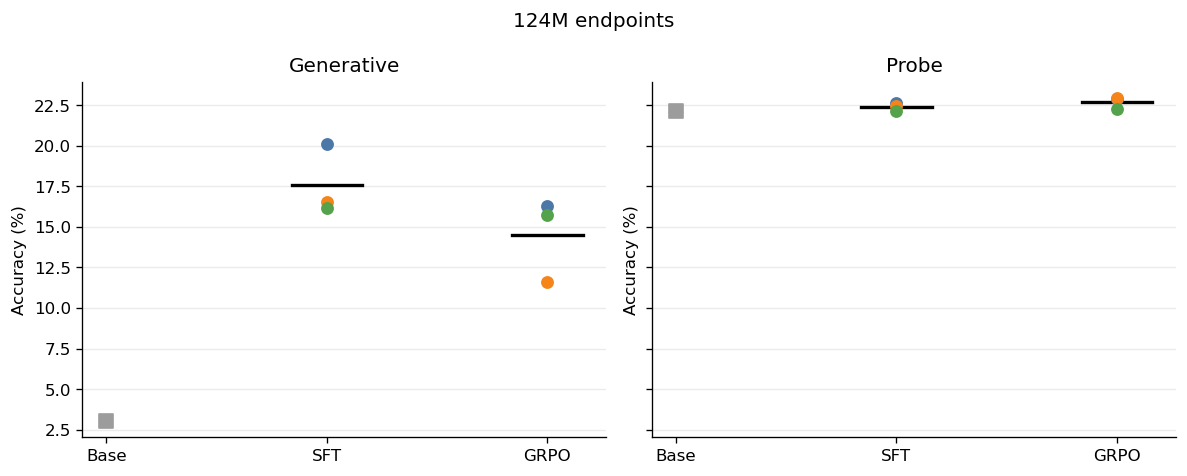

In [3]:
base_dir = RESULTS / '042_COLAB_FULL_M124_base'
base_rows = read_rows(base_dir / 'base_preds.jsonl')
base_probe_rows = read_rows(base_dir / 'base_logprob_preds.jsonl')
base_eval = read_json(base_dir / 'base_eval.json')
base_probe = read_json(base_dir / 'base_logprob.json')

endpoint_rows = []
for metric, base_data, row_key in (
        ('Generative', base_eval, 'rows'), ('Probe', base_probe, 'probe_rows')):
    source_rows = base_rows if metric == 'Generative' else base_probe_rows
    for tier in TIERS + ('overall',):
        value = (base_data['per_tier_acc'][tier] if tier != 'overall'
                 else accuracy(source_rows))
        endpoint_rows.append({'metric': metric, 'stage': 'Base', 'seed': -1,
                              'tier': tier, 'accuracy': value})
    for seed in SEEDS:
        for branch, label in (('sft', 'SFT'), ('grpo', 'GRPO')):
            data = runs[seed][branch]['eval' if metric == 'Generative' else 'probe']
            rows = runs[seed][branch][row_key]
            for tier in TIERS + ('overall',):
                value = data['per_tier_acc'][tier] if tier != 'overall' else accuracy(rows)
                endpoint_rows.append({'metric': metric, 'stage': label, 'seed': seed,
                                      'tier': tier, 'accuracy': value})

endpoint_df = pd.DataFrame(endpoint_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, metric in zip(axes, ('Generative', 'Probe')):
    frame = endpoint_df[(endpoint_df.metric == metric) & (endpoint_df.tier == 'overall')]
    base_value = frame[frame.stage == 'Base'].accuracy.iloc[0]
    ax.scatter(0, base_value * 100, marker='s', s=65, color='#9C9C9C', zorder=3)
    for x, stage in ((1, 'SFT'), (2, 'GRPO')):
        values = frame[frame.stage == stage].sort_values('seed')
        for _, row in values.iterrows():
            ax.scatter(x, row.accuracy * 100, s=45, color=COLORS[int(row.seed)], zorder=3)
        ax.plot([x - .16, x + .16], [values.accuracy.mean() * 100] * 2,
                color='black', linewidth=2)
    ax.set_xticks((0, 1, 2), ('Base', 'SFT', 'GRPO'))
    ax.set_title(metric)
    ax.set_ylabel('Accuracy (%)')
    ax.grid(axis='y', alpha=.25)
fig.suptitle('124M endpoints')
fig.tight_layout()
fig.savefig(FIG / 'fig01_endpoints.png', bbox_inches='tight')
plt.show()

## Registered comparisons

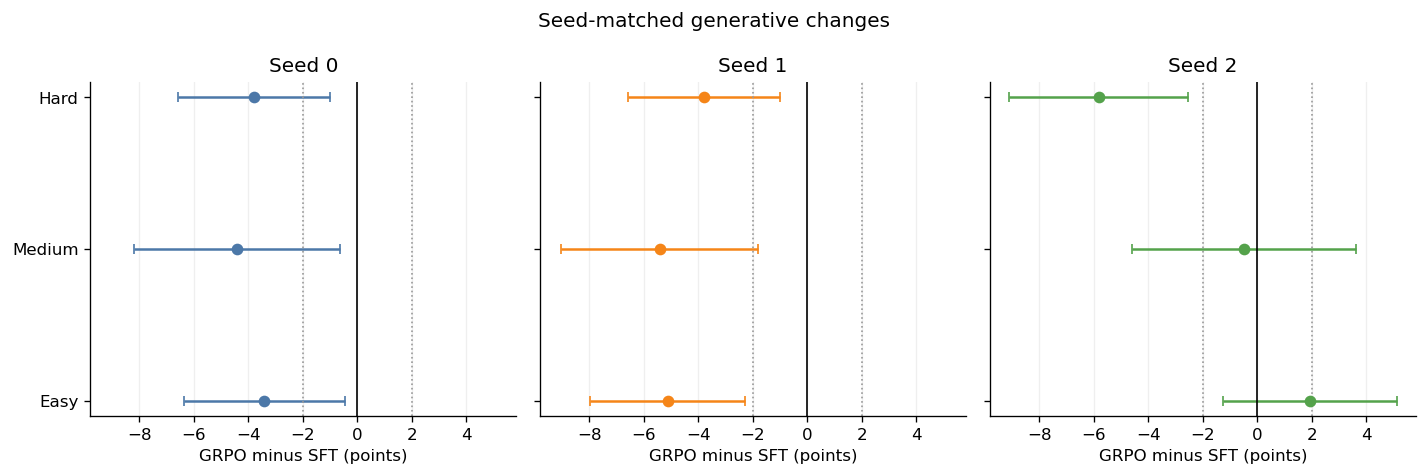

,seed,tier,delta,CI low,CI high,Holm p,category
0,0,easy,-0.034130,-0.063709,-0.004551,0.099503,inconclusive
1,0,medium,-0.044335,-0.082102,-0.006568,0.099503,inconclusive
2,0,hard,-0.037879,-0.065657,-0.010101,0.083369,inconclusive
3,1,easy,-0.051195,-0.079636,-0.022753,0.006009,decline
4,1,medium,-0.054187,-0.090312,-0.018062,0.037280,decline
5,1,hard,-0.037879,-0.065657,-0.010101,0.081186,inconclusive
6,2,easy,0.019340,-0.012514,0.051195,0.522792,inconclusive
7,2,medium,-0.004926,-0.045977,0.036125,0.872441,inconclusive
8,2,hard,-0.058081,-0.090909,-0.025253,0.006593,decline


In [4]:
# calculate paired changes on the aligned test rows
comparison_rows = []
for seed in SEEDS:
    sft_rows, grpo_rows = align_pred_rows(runs[seed]['sft']['rows'],
                                          runs[seed]['grpo']['rows'])
    for tier in TIERS:
        pairs = [(left, right) for left, right in zip(sft_rows, grpo_rows)
                 if left['tier'] == tier]
        before = [bool(left['correct']) for left, _ in pairs]
        after = [bool(right['correct']) for _, right in pairs]
        delta, low, high = paired_delta_ci(before, after, n_boot=10000, seed=seed)
        gains = sum(not left and right for left, right in zip(before, after))
        losses = sum(left and not right for left, right in zip(before, after))
        comparison_rows.append({
            'seed': seed, 'tier': tier, 'SFT': np.mean(before), 'GRPO': np.mean(after),
            'delta': delta, 'CI low': low, 'CI high': high,
            'p': mcnemar_exact(gains, losses), 'gains': gains, 'losses': losses,
        })

adjusted = holm([row['p'] for row in comparison_rows])
for row, value in zip(comparison_rows, adjusted):
    row['Holm p'] = value
    if row['CI low'] > -.02 and row['CI high'] < .02:
        row['category'] = 'equivalent'
    elif row['delta'] >= .02 and value < .05:
        row['category'] = 'improvement'
    elif row['delta'] <= -.02 and value < .05:
        row['category'] = 'decline'
    else:
        row['category'] = 'inconclusive'
comparison_df = pd.DataFrame(comparison_rows)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, seed in zip(axes, SEEDS):
    frame = comparison_df[comparison_df.seed == seed].set_index('tier').loc[list(TIERS)]
    y = np.arange(len(TIERS))
    x = frame.delta.to_numpy() * 100
    xerr = np.vstack((x - frame['CI low'].to_numpy() * 100,
                      frame['CI high'].to_numpy() * 100 - x))
    ax.errorbar(x, y, xerr=xerr, fmt='o', color=COLORS[seed], capsize=3)
    ax.axvline(0, color='black', linewidth=1)
    ax.axvline(-2, color='#999999', linewidth=1, linestyle=':')
    ax.axvline(2, color='#999999', linewidth=1, linestyle=':')
    ax.set_title(f'Seed {seed}')
    ax.set_yticks(y, [tier.title() for tier in TIERS])
    ax.set_xlabel('GRPO minus SFT (points)')
    ax.grid(axis='x', alpha=.2)
fig.suptitle('Seed-matched generative changes')
fig.tight_layout()
fig.savefig(FIG / 'fig02_registered_changes.png', bbox_inches='tight')
plt.show()
display(comparison_df[['seed', 'tier', 'delta', 'CI low', 'CI high', 'Holm p', 'category']])

## Extraction and probe

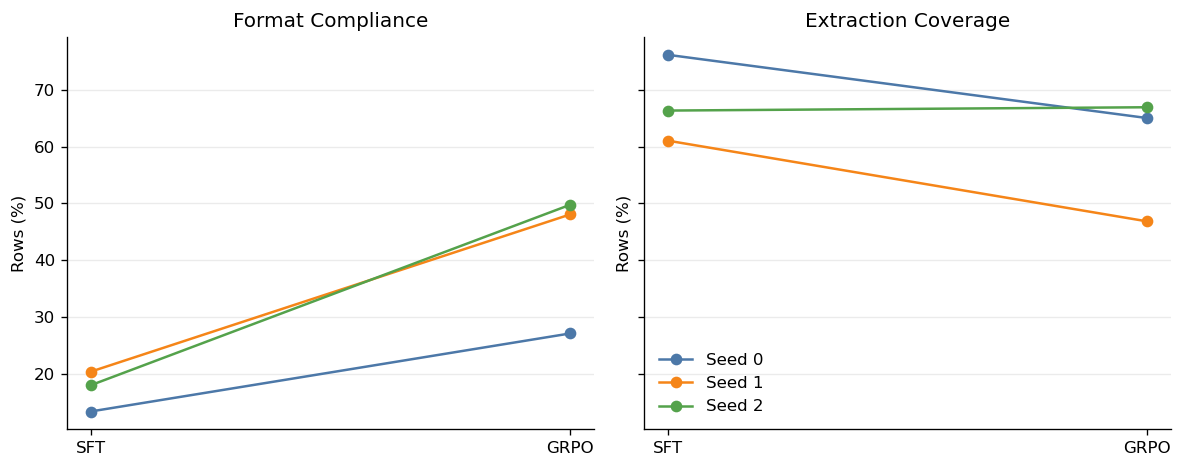

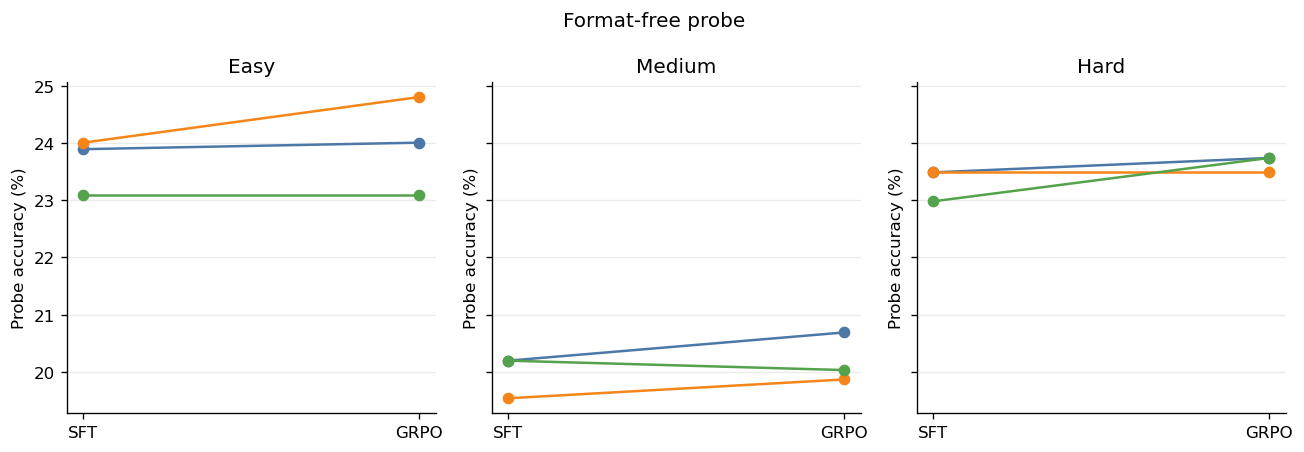

In [5]:
instrument_rows = []
probe_rows = []
for seed in SEEDS:
    for branch, label in (('sft', 'SFT'), ('grpo', 'GRPO')):
        metrics = runs[seed][branch]['eval']
        instrument_rows.append({
            'seed': seed, 'stage': label,
            'format compliance': metrics['format_compliance'],
            'extraction coverage': 1 - metrics['extraction_failure_rate'],
        })
    before, after = align_pred_rows(runs[seed]['sft']['probe_rows'],
                                    runs[seed]['grpo']['probe_rows'])
    for tier in TIERS + ('overall',):
        pairs = [(left, right) for left, right in zip(before, after)
                 if tier == 'overall' or left['tier'] == tier]
        left = [bool(row['correct']) for row, _ in pairs]
        right = [bool(row['correct']) for _, row in pairs]
        delta, low, high = paired_delta_ci(left, right, n_boot=10000, seed=seed)
        gains = sum(not x and y for x, y in zip(left, right))
        losses = sum(x and not y for x, y in zip(left, right))
        probe_rows.append({'seed': seed, 'tier': tier, 'SFT': np.mean(left),
                           'GRPO': np.mean(right), 'delta': delta,
                           'CI low': low, 'CI high': high,
                           'p': mcnemar_exact(gains, losses)})

instrument_df = pd.DataFrame(instrument_rows)
probe_df = pd.DataFrame(probe_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, metric in zip(axes, ('format compliance', 'extraction coverage')):
    for seed in SEEDS:
        values = instrument_df[instrument_df.seed == seed].set_index('stage').loc[['SFT', 'GRPO']]
        ax.plot((0, 1), values[metric].to_numpy() * 100, marker='o',
                color=COLORS[seed], label=f'Seed {seed}')
    ax.set_xticks((0, 1), ('SFT', 'GRPO'))
    ax.set_title(metric.title())
    ax.set_ylabel('Rows (%)')
    ax.grid(axis='y', alpha=.25)
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig03_format_and_extraction.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, tier in zip(axes, TIERS):
    frame = endpoint_df[(endpoint_df.metric == 'Probe') & (endpoint_df.tier == tier)]
    for seed in SEEDS:
        values = frame[frame.seed == seed].set_index('stage').loc[['SFT', 'GRPO']]
        ax.plot((0, 1), values.accuracy.to_numpy() * 100, marker='o',
                color=COLORS[seed])
    ax.set_xticks((0, 1), ('SFT', 'GRPO'))
    ax.set_title(tier.title())
    ax.set_ylabel('Probe accuracy (%)')
    ax.grid(axis='y', alpha=.25)
fig.suptitle('Format-free probe')
fig.tight_layout()
fig.savefig(FIG / 'fig04_probe.png', bbox_inches='tight')
plt.show()

## Training dynamics

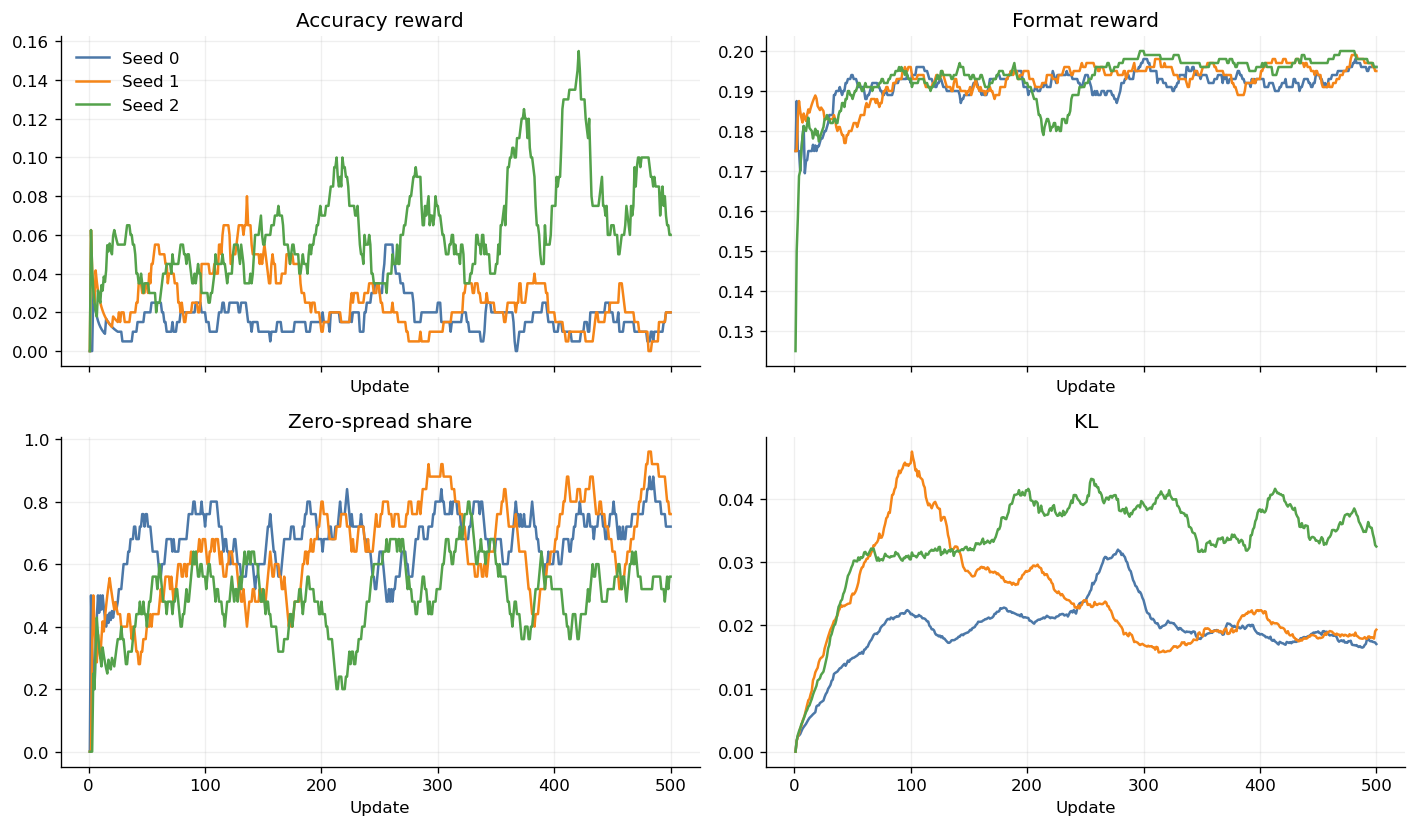

In [6]:
metric_specs = (
    ('rewards/accuracy_reward/mean', 'Accuracy reward'),
    ('rewards/format_reward/mean', 'Format reward'),
    ('frac_reward_zero_std', 'Zero-spread share'),
    ('kl', 'KL'),
)
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (key, title) in zip(axes.flat, metric_specs):
    for seed in SEEDS:
        frame = pd.DataFrame(runs[seed]['trainlog'])
        frame = frame[frame[key].notna()].sort_values('step')
        smooth = frame[key].rolling(25, min_periods=1).mean()
        ax.plot(frame.step, smooth, color=COLORS[seed], label=f'Seed {seed}')
    ax.set_title(title)
    ax.set_xlabel('Update')
    ax.grid(alpha=.2)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig05_training_dynamics.png', bbox_inches='tight')
plt.show()

## Exact values

In [7]:
training_rows = []
for seed in SEEDS:
    summary = runs[seed]['training']['starvation']['complete']
    trainlog = pd.DataFrame(runs[seed]['trainlog'])
    training_rows.append({
        'seed': seed,
        **summary,
        'mean KL': trainlog.kl.dropna().mean(),
        'maximum KL': trainlog.kl.dropna().max(),
        'severely reward starved': runs[seed]['training']['starvation']['severely_reward_starved'],
    })
training_df = pd.DataFrame(training_rows)

endpoint_df.to_csv(FIG / '042_1_endpoints.csv', index=False)
comparison_df.to_csv(FIG / '042_1_registered_comparisons.csv', index=False)
instrument_df.to_csv(FIG / '042_1_instrument_checks.csv', index=False)
probe_df.to_csv(FIG / '042_1_probe_comparisons.csv', index=False)
training_df.to_csv(FIG / '042_1_training_summary.csv', index=False)

tier_summary = (comparison_df.groupby('tier').delta
                .agg(['mean', 'min', 'max']).loc[list(TIERS)])
display(tier_summary.style.format('{:.4f}'))
display(instrument_df.pivot(index='seed', columns='stage',
                            values=['format compliance', 'extraction coverage'])
        .style.format('{:.2%}'))
display(training_df.style.format(precision=4))

,mean,min,max
tier,,,
easy,-0.0220,-0.0512,0.0193
medium,-0.0345,-0.0542,-0.0049
hard,-0.0446,-0.0581,-0.0379


,seed,mean_accuracy_reward,mean_format_reward,share_zero_reward_spread,mean KL,maximum KL,severely reward starved
0,0,0.0173,0.1920,0.6860,0.0197,0.0433,False
1,1,0.0262,0.1927,0.6540,0.0241,0.0800,False
2,2,0.0645,0.1937,0.5000,0.0344,0.0834,False


## Cross-referenced conclusion

Three registered pipelines completed and passed their integrity gates. SFT raises mean generative accuracy from the 3.03% base result to 17.60%, while GRPO lowers it to 14.53%. Mean decline is largest on hard questions, where all three seeds move downward.

GRPO improves tagged format compliance from 17.20% to 41.61%, but extraction coverage changes enough to make seeds 0 and 1 instrument limited. The format free probe changes by only about +0.3 points and no probe tier is significant after correction. My conclusion is that this GRPO recipe doesn't add detectable MMLU knowledge at the 124M GPT-2 boundary. It changes response behaviour, but the result does not prove a universal model size threshold and must remain separate from the Qwen2.5 scale curve.